In [3]:
import kagglehub
path = kagglehub.dataset_download("uciml/iris")

Using Colab cache for faster access to the 'iris' dataset.


# Instalação da FLAML

In [2]:
!pip install flaml[automl]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 24.9 MB/s  0:00:08
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.5/336.5 MB 31.7 MB/s  0:00:09
  Attempting uninstall: xgboost
    Found existing installation: xgboost 3.4.1
    Uninstalling xgboost-3.4.1:
      Successfully uninstalled xgboost-3.4.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [xgboost]


 # Importação das bibliotecas

In [4]:
import os
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from flaml import AutoML

# Configuração visual do Seaborn
sns.set_theme(style="whitegrid")



# Carregamento e Visualização do Dataset Iris

In [7]:
csv_files = [
    f for f in os.listdir(path)
    if f.endswith(".csv")
]

csv_file = csv_files[0]

df_iris = pd.read_csv(
    os.path.join(path, csv_file)
)

print("Dataset Iris carregado com sucesso!")

print(
    f"Dimensões do Dataset: "
    f"{df_iris.shape[0]} linhas e "
    f"{df_iris.shape[1]} colunas\n"
)

print("Primeiras 5 linhas:")

display(df_iris.head())

Dataset Iris carregado com sucesso!
Dimensões do Dataset: 150 linhas e 6 colunas

Primeiras 5 linhas:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Nesta etapa, o arquivo CSV do dataset Iris é localizado e carregado utilizando a biblioteca Pandas. Em seguida, são exibidas suas dimensões e as cinco primeiras linhas para verificar a estrutura dos dados.

# Análise Exploratória dos Dados (EDA)

1. Informações Gerais do Dataset 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

 2. Estatísticas Descritivas 


,count,mean,std,min,25%,50%,75%,max
Id,150.0,75.500000,43.445368,1.0,38.25,75.50,112.75,150.0
SepalLengthCm,150.0,5.843333,0.828066,4.3,5.10,5.80,6.40,7.9
SepalWidthCm,150.0,3.054000,0.433594,2.0,2.80,3.00,3.30,4.4
PetalLengthCm,150.0,3.758667,1.764420,1.0,1.60,4.35,5.10,6.9
PetalWidthCm,150.0,1.198667,0.763161,0.1,0.30,1.30,1.80,2.5



 3. Verificação de Valores Nulos 
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

 4. Contagem de Classes (Espécies) 
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


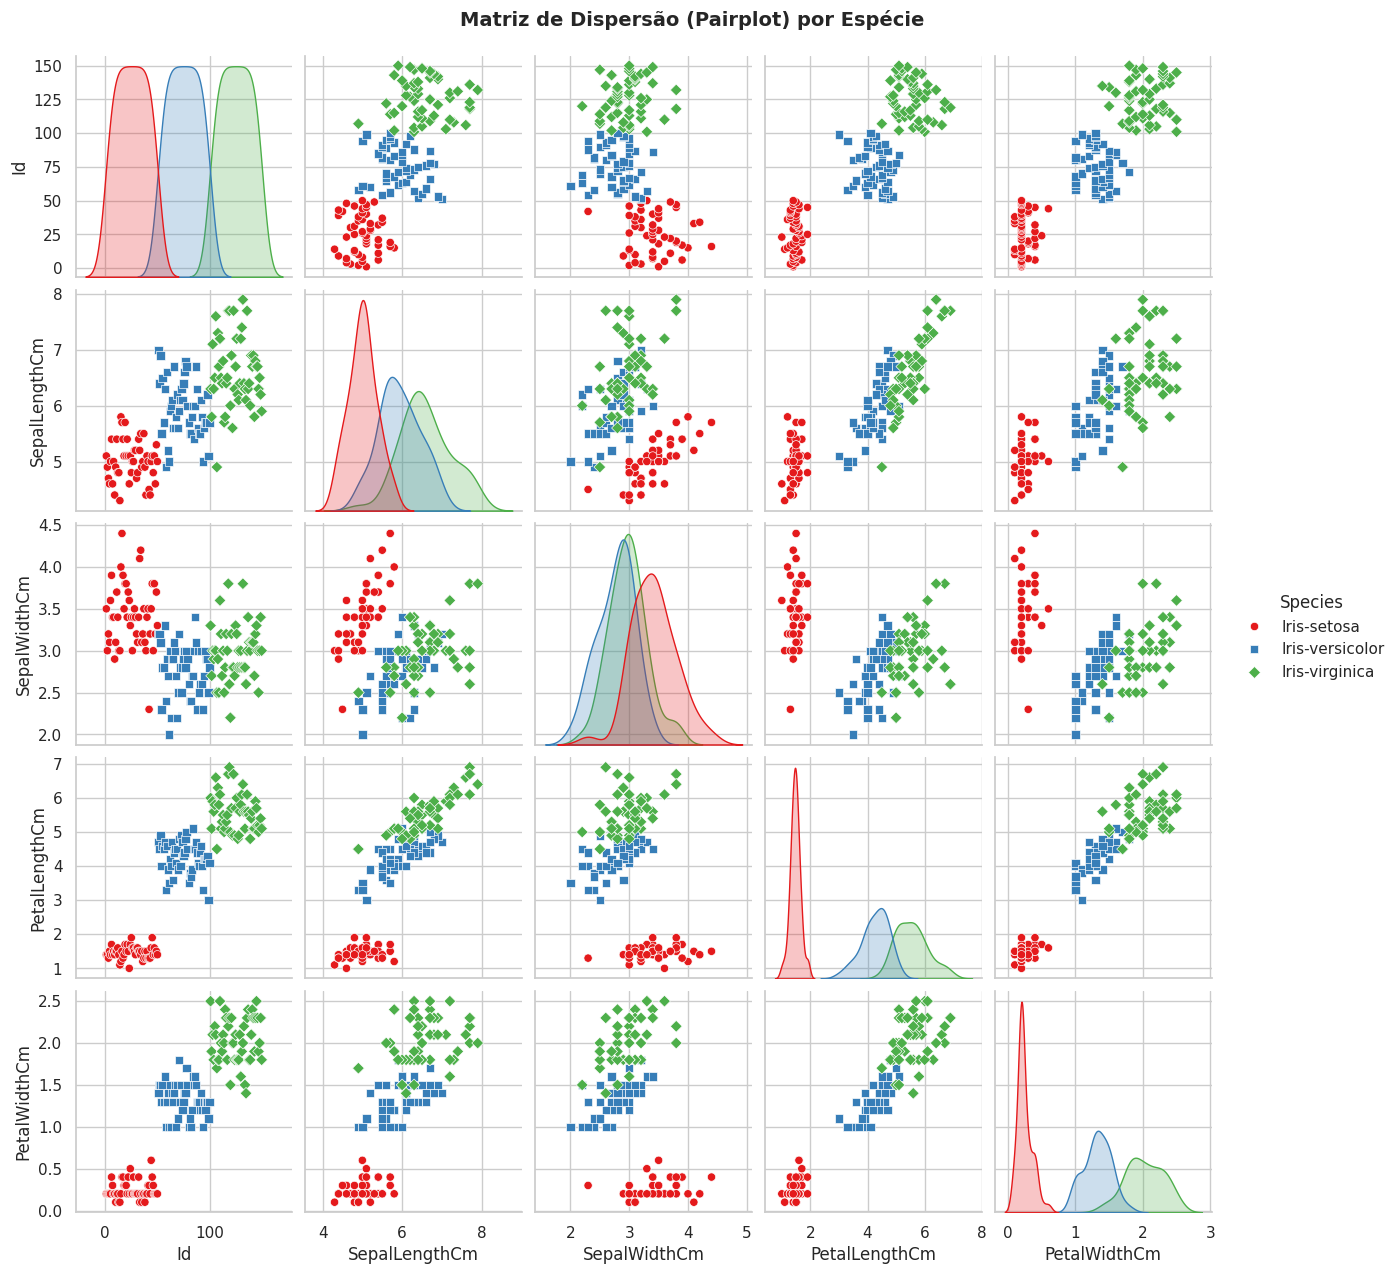

In [8]:
print("1. Informações Gerais do Dataset ")

df_iris.info()

print("\n 2. Estatísticas Descritivas ")

display(df_iris.describe().T)

print("\n 3. Verificação de Valores Nulos ")

print(df_iris.isnull().sum())

print("\n 4. Contagem de Classes (Espécies) ")

print(df_iris["Species"].value_counts())

sns.pairplot(
    df_iris,
    hue="Species",
    palette="Set1",
    markers=["o", "s", "D"]
)

plt.suptitle(
    "Matriz de Dispersão (Pairplot) por Espécie",
    y=1.02,
    fontsize=14,
    fontweight="bold"
)

plt.show()

Nesta etapa, é realizada a análise exploratória do dataset Iris para compreender sua estrutura, características, distribuição das espécies e possíveis valores ausentes. Também é gerada uma matriz de dispersão (*Pairplot*) para visualizar a relação entre as variáveis e identificar a separabilidade entre as diferentes espécies de flores.

# 4. Pré-processamento e Divisão dos Dados

Nesta etapa, os dados são preparados para o treinamento dos modelos, com a remoção da coluna de identificação, separação das variáveis preditoras e codificação das espécies. Em seguida, o dataset é dividido em 80% para treinamento e 20% para teste, utilizando estratificação e uma semente fixa para garantir a reprodutibilidade dos resultados.

In [9]:
if "Id" in df_iris.columns:
    df_iris = df_iris.drop(columns=["Id"])
    print("Coluna 'Id' removida com sucesso.")

X = df_iris.drop(columns=["Species"])
y_raw = df_iris["Species"]

le = LabelEncoder()
y = le.fit_transform(y_raw)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

#==============================================================================================

print("\n RESUMO DA DIVISÃO DOS DADOS ")

print(
    f"Conjunto de Treino (X_train): "
    f"{X_train.shape[0]} amostras"
)

print(
    f"Conjunto de Teste (X_test): "
    f"{X_test.shape[0]} amostras"
)

print(
    f"Mapeamento de Classes: "
    f"{dict(zip(le.classes_, range(len(le.classes_)) ))}"
)

Coluna 'Id' removida com sucesso.

 RESUMO DA DIVISÃO DOS DADOS 
Conjunto de Treino (X_train): 120 amostras
Conjunto de Teste (X_test): 30 amostras
Mapeamento de Classes: {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}


# Treinamento e Avaliação do FLAML

Nesta etapa, o framework FLAML é utilizado para realizar a classificação automática das espécies do dataset Iris. O treinamento possui um limite de 60 segundos e utiliza a acurácia como métrica de otimização. Após a execução, são realizadas previsões no conjunto de teste e apresentados o tempo de execução, o algoritmo selecionado, os melhores hiperparâmetros e as métricas de desempenho.

In [10]:
automl_flaml = AutoML()

settings_flaml = {
    "time_budget": 60,
    "metric": "accuracy",
    "task": "classification",
    "seed": 42,
    "verbose": 0
}

inicio_flaml = time.time()

automl_flaml.fit(
    X_train=X_train,
    y_train=y_train,
    **settings_flaml
)

tempo_flaml = time.time() - inicio_flaml

y_pred_flaml = automl_flaml.predict(X_test)

acc_flaml = accuracy_score(y_test, y_pred_flaml)

print("=" * 50)
print("          RESULTADOS DO FLAML")
print("=" * 50)

print(f"\nTempo de execução: {tempo_flaml:.2f} segundos")
print(f"Algoritmo selecionado: {automl_flaml.best_estimator}")
print(f"Melhores hiperparâmetros: {automl_flaml.best_config}")
print(f"Acurácia no conjunto de teste: {acc_flaml * 100:.2f}%")

print("\n" + "=" * 50)
print("       RELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 50)

print(
    classification_report(
        y_test,
        y_pred_flaml,
        target_names=le.classes_
    )
)

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune
INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


          RESULTADOS DO FLAML

Tempo de execução: 60.06 segundos
Algoritmo selecionado: lrl1
Melhores hiperparâmetros: {'C': np.float64(1.0)}
Acurácia no conjunto de teste: 100.00%

       RELATÓRIO DE CLASSIFICAÇÃO
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



# 5.1. Matriz de Confusão — FLAML

Nesta etapa, é gerada a matriz de confusão para visualizar o desempenho do FLAML na classificação das espécies do dataset Iris, permitindo identificar os acertos e erros entre as classes reais e previstas pelo modelo.

<Figure size 600x400 with 0 Axes>

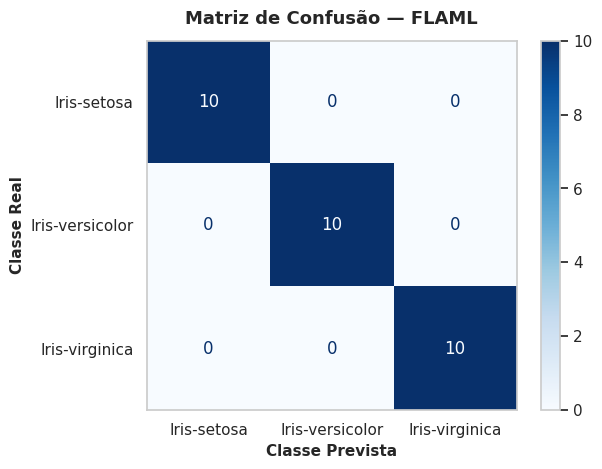

In [11]:
cm_flaml = confusion_matrix(y_test, y_pred_flaml)

plt.figure(figsize=(6, 4))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_flaml,
    display_labels=le.classes_
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Matriz de Confusão — FLAML",
    fontsize=13,
    fontweight="bold",
    pad=12
)

plt.xlabel("Classe Prevista", fontsize=11, fontweight="bold")
plt.ylabel("Classe Real", fontsize=11, fontweight="bold")

plt.grid(False)
plt.show()

# Auto-Sklearn

## Instalação e Configuração do Python 3.9

Nesta etapa, são atualizados os pacotes do sistema e instalados o Python 3.9, suas dependências de desenvolvimento e ferramentas necessárias para a instalação do Auto-Sklearn. Ao final, é verificada a versão do Python instalada.

In [23]:
!apt-get update -qq

!apt-get install -y python3.9 python3.9-dev python3.9-venv swig build-essential

!python3.9 --version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
python3.9 is already the newest version (3.9.25-1+noble1).
python3.9-dev is already the newest version (3.9.25-1+noble1).
python3.9-venv is already the newest version (3.9.25-1+noble1).
swig is already the newest version (4.2.0-2ubuntu1).
build-essential is already the newest version (12.10ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 48 not upgraded.
Python 3.9.25


## Configuração do Ambiente Virtual e Instalação do Auto-Sklearn

Nesta etapa, é criado um ambiente virtual com Python 3.9 para instalar o Auto-Sklearn 0.15.0 e suas dependências em versões compatíveis. Após a configuração, o script responsável pelo treinamento do modelo é executado.

In [24]:
!python3.9 -m venv /content/venv39

!/content/venv39/bin/python -m pip install --upgrade pip

!/content/venv39/bin/python -m pip install "setuptools==65.5.0" wheel

!/content/venv39/bin/python -m pip install --no-build-isolation "auto-sklearn==0.15.0"

!/content/venv39/bin/python /content/treinar_autosklearn.py

  Using cached setuptools-65.5.0-py3-none-any.whl.metadata (6.3 kB)
Using cached setuptools-65.5.0-py3-none-any.whl (1.2 MB)
  Attempting uninstall: setuptools
    Found existing installation: setuptools 79.0.1
    Uninstalling setuptools-79.0.1:
      Successfully uninstalled setuptools-79.0.1
/content/venv39/bin/python: can't open file '/content/treinar_autosklearn.py': [Errno 2] No such file or directory


In [14]:
!/content/venv39/bin/python -m pip install --force-reinstall \
    "numpy==1.23.5" \
    "scipy==1.9.3"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.1/17.1 MB 30.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.8/33.8 MB 26.9 MB/s  0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
  Attempting uninstall: scipy
    Found existing installation: scipy 1.13.1
    Uninstalling scipy-1.13.1:
      Successfully uninstalled scipy-1.13.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [scipy]


In [15]:
!/content/venv39/bin/python -c "import sys, numpy, scipy, sklearn, autosklearn; print('Python:', sys.version); print('NumPy:', numpy.__version__); print('SciPy:', scipy.__version__); print('Scikit-learn:', sklearn.__version__); print('Auto-Sklearn:', autosklearn.__version__); print('INSTALAÇÃO OK')"

Python: 3.9.25 (main, Nov  7 2025, 18:07:57) 
[GCC 13.3.0]
NumPy: 1.23.5
SciPy: 1.9.3
Scikit-learn: 0.24.2
Auto-Sklearn: 0.15.0
INSTALAÇÃO OK


In [26]:
import time

from flaml import AutoML
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

modelo_flaml = AutoML()

configuracoes = {
    "time_budget": 60,
    "metric": "accuracy",
    "task": "classification",
    "seed": 42,
    "estimator_list": ["lgbm", "rf", "extra_tree", "xgboost"]
}

inicio = time.time()

modelo_flaml.fit(
    X_train=X_train,
    y_train=y_train,
    **configuracoes
)

tempo_execucao = time.time() - inicio

previsoes = modelo_flaml.predict(X_test)

acuracia = accuracy_score(y_test, previsoes)

print("\n===== RESULTADOS FLAML =====")
print(f"Modelo escolhido: {modelo_flaml.best_estimator}")
print(f"Tempo de execução: {tempo_execucao:.2f} segundos")
print(f"Acurácia: {acuracia:.4f}")

print("\n===== RELATÓRIO DE CLASSIFICAÇÃO =====")
print(classification_report(
    y_test,
    previsoes,
    target_names=iris.target_names
))

print("\n===== CONFIGURAÇÃO DO MELHOR MODELO =====")
print(modelo_flaml.best_config)

[flaml.automl.logger: 11-14 02:51:24] {2484} INFO - task = classification
[flaml.automl.logger: 11-14 02:51:24] {2495} INFO - Evaluation method: cv
[flaml.automl.logger: 11-14 02:51:24] {2604} INFO - Minimizing error metric: 1-accuracy
[flaml.automl.logger: 11-14 02:51:24] {2721} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'extra_tree', 'xgboost']
[flaml.automl.logger: 11-14 02:51:24] {3026} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 11-14 02:51:24] {3161} INFO - Estimated sufficient time budget=442s. Estimated necessary time budget=0s.
[flaml.automl.logger: 11-14 02:51:24] {3212} INFO -  at 0.1s,	estimator lgbm's best error=5.8333e-02,	best estimator lgbm's best error=5.8333e-02
[flaml.automl.logger: 11-14 02:51:24] {3026} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 11-14 02:51:24] {3212} INFO -  at 0.1s,	estimator lgbm's best error=5.8333e-02,	best estimator lgbm's best error=5.8333e-02
[flaml.automl.logger: 11-14 02:51:24] {3026} I

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

[flaml.automl.logger: 11-14 02:51:24] {3212} INFO -  at 0.3s,	estimator lgbm's best error=5.8333e-02,	best estimator xgboost's best error=5.0000e-02
[flaml.automl.logger: 11-14 02:51:24] {3026} INFO - iteration 5, current learner lgbm
[flaml.automl.logger: 11-14 02:51:24] {3212} INFO -  at 0.3s,	estimator lgbm's best error=5.8333e-02,	best estimator xgboost's best error=5.0000e-02
[flaml.automl.logger: 11-14 02:51:24] {3026} INFO - iteration 6, current learner lgbm
[flaml.automl.logger: 11-14 02:51:24] {3212} INFO -  at 0.3s,	estimator lgbm's best error=5.8333e-02,	best estimator xgboost's best error=5.0000e-02
[flaml.automl.logger: 11-14 02:51:24] {3026} INFO - iteration 7, current learner lgbm
[flaml.automl.logger: 11-14 02:51:24] {3212} INFO -  at 0.4s,	estimator lgbm's best error=5.8333e-02,	best estimator xgboost's best error=5.0000e-02
[flaml.automl.logger: 11-14 02:51:24] {3026} INFO - iteration 8, current learner lgbm
[flaml.automl.logger: 11-14 02:51:24] {3212} INFO -  at 0.4s

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

[flaml.automl.logger: 11-14 02:51:24] {3212} INFO -  at 0.5s,	estimator xgboost's best error=4.1667e-02,	best estimator xgboost's best error=4.1667e-02
[flaml.automl.logger: 11-14 02:51:24] {3026} INFO - iteration 10, current learner xgboost
[flaml.automl.logger: 11-14 02:51:24] {3212} INFO -  at 0.6s,	estimator xgboost's best error=4.1667e-02,	best estimator xgboost's best error=4.1667e-02
[flaml.automl.logger: 11-14 02:51:24] {3026} INFO - iteration 11, current learner extra_tree
[flaml.automl.logger: 11-14 02:51:24] {3212} INFO -  at 0.8s,	estimator extra_tree's best error=1.5833e-01,	best estimator xgboost's best error=4.1667e-02
[flaml.automl.logger: 11-14 02:51:24] {3026} INFO - iteration 12, current learner xgboost
[flaml.automl.logger: 11-14 02:51:24] {3212} INFO -  at 0.8s,	estimator xgboost's best error=4.1667e-02,	best estimator xgboost's best error=4.1667e-02
[flaml.automl.logger: 11-14 02:51:24] {3026} INFO - iteration 13, current learner rf
[flaml.automl.logger: 11-14 02:

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

... (154 outputs left out)

[flaml.automl.logger: 11-14 02:52:21] {3212} INFO -  at 57.2s,	estimator lgbm's best error=3.3333e-02,	best estimator lgbm's best error=3.3333e-02
[flaml.automl.logger: 11-14 02:52:21] {3026} INFO - iteration 358, current learner extra_tree
[flaml.automl.logger: 11-14 02:52:21] {3212} INFO -  at 57.6s,	estimator extra_tree's best error=3.3333e-02,	best estimator lgbm's best error=3.3333e-02
[flaml.automl.logger: 11-14 02:52:21] {3026} INFO - iteration 359, current learner rf
[flaml.automl.logger: 11-14 02:52:21] {3212} INFO -  at 57.8s,	estimator rf's best error=4.1667e-02,	best estimator lgbm's best error=3.3333e-02
[flaml.automl.logger: 11-14 02:52:21] {3026} INFO - iteration 360, current learner xgboost
[flaml.automl.logger: 11-14 02:52:22] {3212} INFO -  at 58.0s,	estimator xgboost's best error=4.1667e-02,	best estimator lgbm's best error=3.3333e-02
[flaml.automl.logger: 11-14 02:52:22] {3026} INFO - iteration 361, current learner rf
[flaml.automl.logger: 11-14 02:52:22] {3212} INF

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

[flaml.automl.logger: 11-14 02:52:23] {3026} INFO - iteration 366, current learner xgboost
[flaml.automl.logger: 11-14 02:52:23] {3212} INFO -  at 59.8s,	estimator xgboost's best error=4.1667e-02,	best estimator lgbm's best error=3.3333e-02
[flaml.automl.logger: 11-14 02:52:23] {3026} INFO - iteration 367, current learner rf
[flaml.automl.logger: 11-14 02:52:24] {3212} INFO -  at 60.0s,	estimator rf's best error=4.1667e-02,	best estimator lgbm's best error=3.3333e-02
[flaml.automl.logger: 11-14 02:52:24] {3474} INFO - retrain lgbm for 0.1s
[flaml.automl.logger: 11-14 02:52:24] {3477} INFO - retrained model: LGBMClassifier(learning_rate=np.float64(0.7088624964104729), max_bin=255,
               min_child_samples=26, n_estimators=17, n_jobs=-1, num_leaves=5,
               reg_alpha=np.float64(0.031053314852989265),
               reg_lambda=np.float64(0.28811162808869856), verbose=-1)
[flaml.automl.logger: 11-14 02:52:24] {2751} INFO - fit succeeded
[flaml.automl.logger: 11-14 02:52:24

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


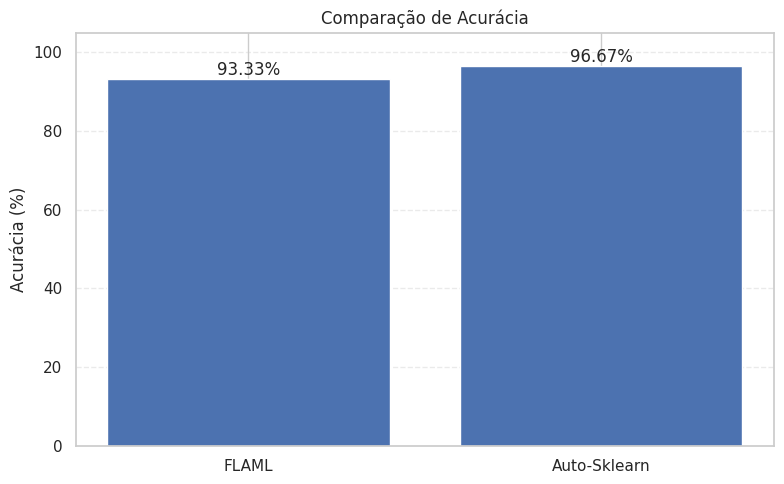

In [27]:
# ============================================================
# 1. GRÁFICO COMPARATIVO DE ACURÁCIA
# ============================================================

frameworks = ["FLAML", "Auto-Sklearn"]
acuracias = [93.33, 96.67]

plt.figure(figsize=(8, 5))
barras = plt.bar(frameworks, acuracias)

plt.title("Comparação de Acurácia")
plt.ylabel("Acurácia (%)")
plt.ylim(0, 105)
plt.grid(axis="y", linestyle="--", alpha=0.4)

for barra, valor in zip(barras, acuracias):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 1,
        f"{valor:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()



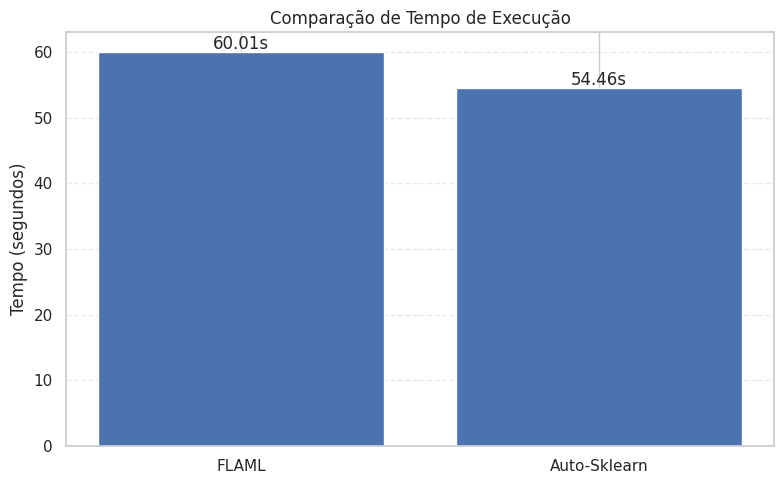

In [28]:
# ============================================================
# 2. GRÁFICO COMPARATIVO DE TEMPO DE EXECUÇÃO
# ============================================================

tempos = [60.01, 54.46]

plt.figure(figsize=(8, 5))
barras = plt.bar(frameworks, tempos)

plt.title("Comparação de Tempo de Execução")
plt.ylabel("Tempo (segundos)")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for barra, valor in zip(barras, tempos):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.5,
        f"{valor:.2f}s",
        ha="center"
    )

plt.tight_layout()
plt.show()


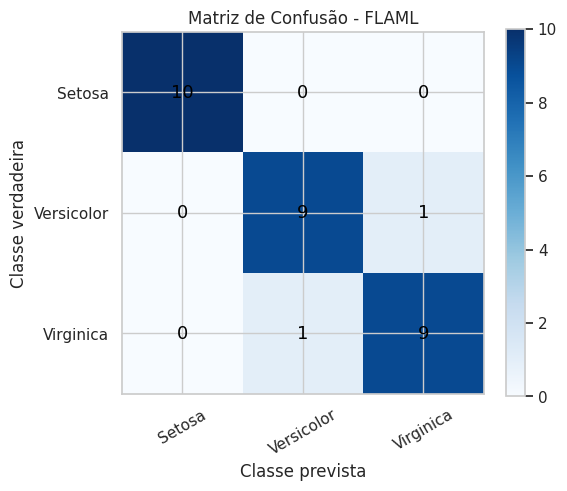

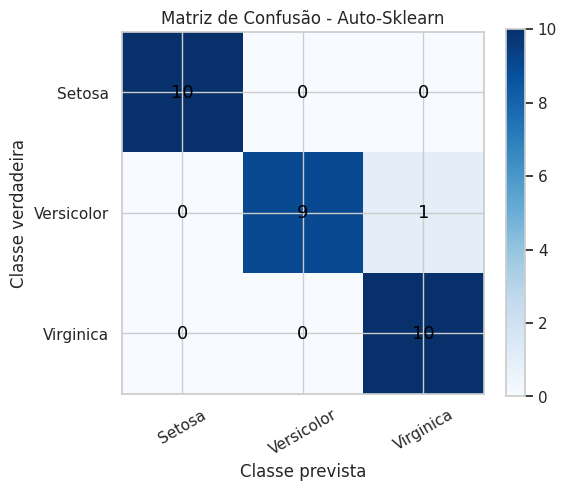

In [29]:

# ============================================================
# 3. MATRIZES DE CONFUSÃO
# ============================================================

nomes_classes = ["Setosa", "Versicolor", "Virginica"]

matriz_flaml = np.array([
    [10, 0, 0],
    [0, 9, 1],
    [0, 1, 9]
])

matriz_autosklearn = np.array([
    [10, 0, 0],
    [0, 9, 1],
    [0, 0, 10]
])


def exibir_matriz(matriz, titulo):

    plt.figure(figsize=(6, 5))

    plt.imshow(matriz, cmap="Blues")
    plt.title(titulo)
    plt.colorbar()

    plt.xticks(range(3), nomes_classes, rotation=30)
    plt.yticks(range(3), nomes_classes)

    plt.xlabel("Classe prevista")
    plt.ylabel("Classe verdadeira")

    for linha in range(3):
        for coluna in range(3):
            plt.text(
                coluna,
                linha,
                matriz[linha, coluna],
                ha="center",
                va="center",
                color="black",
                fontsize=13
            )

    plt.tight_layout()
    plt.show()


exibir_matriz(matriz_flaml, "Matriz de Confusão - FLAML")
exibir_matriz(matriz_autosklearn, "Matriz de Confusão - Auto-Sklearn")